# LAB 12 : Random Forest Classification Using Iris Dataset

Task 1: Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

# Load dataset and separate features from target species labels
iris_bundle = load_iris()
flower_features = iris_bundle.data
species_labels = iris_bundle.target
feature_labels = iris_bundle.feature_names
species_names = iris_bundle.target_names

print(f"Feature matrix shape: {flower_features.shape}")
print(f"Target vector shape: {species_labels.shape}")
print(f"Classes: {list(species_names)}")

Feature matrix shape: (150, 4)
Target vector shape: (150,)
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [2]:
feat_train, feat_test, target_train, target_test = train_test_split(
    flower_features,
    species_labels,
    test_size=0.20,
    random_state=42
)

print(f"Training samples: {feat_train.shape[0]} | Testing samples: {feat_test.shape[0]}")

Training samples: 120 | Testing samples: 30


Task 2: Random Forest Model Development

In [3]:
forest_clf = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    random_state=42
)

# Fit the model on training data and generate predictions on test data
forest_clf.fit(feat_train, target_train)
predicted_species = forest_clf.predict(feat_test)

print("Sample Predictions vs. Actual Species (first 10 test records):")
for idx in range(10):
    print(f"Sample {idx + 1:2d} -> Predicted: {species_names[predicted_species[idx]]:10s} | Actual: {species_names[target_test[idx]]}")

Sample Predictions vs. Actual Species (first 10 test records):
Sample  1 -> Predicted: versicolor | Actual: versicolor
Sample  2 -> Predicted: setosa     | Actual: setosa
Sample  3 -> Predicted: virginica  | Actual: virginica
Sample  4 -> Predicted: versicolor | Actual: versicolor
Sample  5 -> Predicted: versicolor | Actual: versicolor
Sample  6 -> Predicted: setosa     | Actual: setosa
Sample  7 -> Predicted: versicolor | Actual: versicolor
Sample  8 -> Predicted: virginica  | Actual: virginica
Sample  9 -> Predicted: versicolor | Actual: versicolor
Sample 10 -> Predicted: versicolor | Actual: versicolor


Task 3: Performance Evaluation

In [4]:
test_acc = accuracy_score(target_test, predicted_species)
print(f"Random Forest Testing Accuracy: {test_acc * 100:.2f}%\n")

conf_mat = confusion_matrix(target_test, predicted_species)
conf_df = pd.DataFrame(
    conf_mat,
    index=[f"Actual: {name}" for name in species_names],
    columns=[f"Pred: {name}" for name in species_names]
)
print("Confusion Matrix:")
print(conf_df)

Random Forest Testing Accuracy: 100.00%

Confusion Matrix:
                    Pred: setosa  Pred: versicolor  Pred: virginica
Actual: setosa                10                 0                0
Actual: versicolor             0                 9                0
Actual: virginica              0                 0               11


In [5]:
prec, rec, f1, _ = precision_recall_fscore_support(
    target_test,
    predicted_species,
    average="weighted"
)

print(f"Weighted Precision : {prec:.4f}")
print(f"Weighted Recall    : {rec:.4f}")
print(f"Weighted F1-Score  : {f1:.4f}\n")

print("Detailed Per-Class Classification Report:")
print(classification_report(target_test, predicted_species, target_names=species_names))

Weighted Precision : 1.0000
Weighted Recall    : 1.0000
Weighted F1-Score  : 1.0000

Detailed Per-Class Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Feature Importance Ranking:
          Feature  Importance Score
petal length (cm)          0.439994
 petal width (cm)          0.421522
sepal length (cm)          0.108098
 sepal width (cm)          0.030387


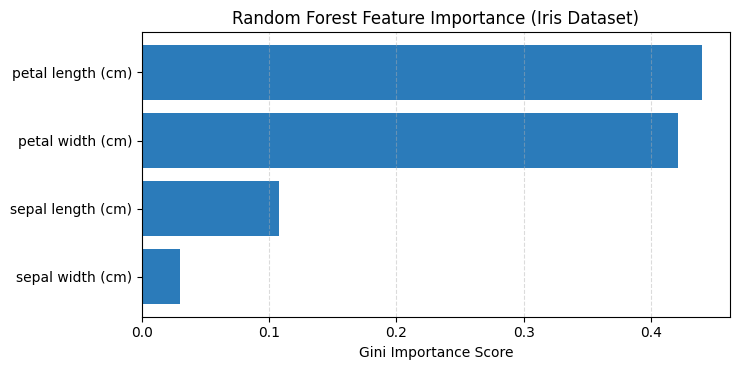

In [6]:
importance_df = pd.DataFrame({
    "Feature": feature_labels,
    "Importance Score": forest_clf.feature_importances_
}).sort_values(by="Importance Score", ascending=False).reset_index(drop=True)

print("Feature Importance Ranking:")
print(importance_df.to_string(index=False))

# Visualize feature importance scores
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(importance_df["Feature"][::-1], importance_df["Importance Score"][::-1], color="#2b7bba")
ax.set_xlabel("Gini Importance Score")
ax.set_title("Random Forest Feature Importance (Iris Dataset)")
ax.grid(axis="x", linestyle="--", alpha=0.45)
plt.tight_layout()
plt.show()

Task 4: Comparative Analysis

In [7]:
candidate_models = {
    "Decision Tree": DecisionTreeClassifier(criterion="gini", random_state=42),
    "Random Forest (10 Trees)": RandomForestClassifier(n_estimators=10, criterion="gini", random_state=42),
    "Random Forest (50 Trees)": RandomForestClassifier(n_estimators=50, criterion="gini", random_state=42),
    "Random Forest (100 Trees)": RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)
}

benchmark_rows = []
for model_label, estimator in candidate_models.items():
    estimator.fit(feat_train, target_train)
    preds = estimator.predict(feat_test)
    acc = accuracy_score(target_test, preds)
    benchmark_rows.append({
        "Model": model_label,
        "Testing Accuracy": f"{acc * 100:.2f}% ({acc:.4f})"
    })

comparison_df = pd.DataFrame(benchmark_rows)
print(comparison_df.to_string(index=False))

                    Model Testing Accuracy
            Decision Tree 100.00% (1.0000)
 Random Forest (10 Trees) 100.00% (1.0000)
 Random Forest (50 Trees) 100.00% (1.0000)
Random Forest (100 Trees) 100.00% (1.0000)
